# Trends and anomalies from a satellite time series

This tutorial runs offline in about a minute. It builds a synthetic monthly NDVI record **where the true answer is known**:
a greening area, a browning patch and a summer drought. It then checks that the methods in `eolandscape` recover them.

You will:

1. hold the data as a labelled `xarray` cube (time, y, x);
2. make growing-season composites and test for trends with Theil–Sen and Mann–Kendall;
3. see why significance maps need a multiple-testing correction (Benjamini–Hochberg);
4. compute a 30-year monthly climatology and standardized anomalies;
5. run the same analysis lazily on chunked (dask) data and get identical numbers.

With real data, step 1 is replaced by a STAC search and load (see the end of the notebook). Everything after it is the same.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from eolandscape import xr as exr

plt.rcParams.update({"figure.dpi": 90, "image.origin": "upper"})

## 1. A synthetic NDVI cube with known trends

- 40 × 40 pixels of 100 m, monthly from 1991 to 2024.
- Seasonal cycle peaking in July, Gaussian noise, and 10 % of observations lost to clouds (NaN).
- **Known trends:** +0.004 NDVI/yr in an eastern strip, −0.006 NDVI/yr in a western patch, none elsewhere (most of the map, as in most real landscapes).
- **Known drought:** June–August 2022, −0.12 NDVI in the south-west quarter.

In [2]:
rng = np.random.default_rng(42)
times = pd.date_range("1991-01-01", "2024-12-01", freq="MS")
ny, nx, res = 40, 40, 100.0
y = 4_500_050.0 - res * np.arange(ny)          # metres, north-up (illustrative projected grid)
x = 5_200_050.0 + res * np.arange(nx)

true_trend = np.zeros((ny, nx))
true_trend[:, 28:] = 0.004                       # greening (NDVI per year)
true_trend[5:15, 3:13] = -0.006                  # browning patch
zone = np.full((ny, nx), "no trend", dtype=object)
zone[:, 28:] = "greening"
zone[5:15, 3:13] = "browning"

years_since = (times.year - 1991 + (times.month - 0.5) / 12).to_numpy()
season = 0.45 + 0.2 * np.cos(2 * np.pi * (times.month.to_numpy() - 7) / 12)
values = (season[:, None, None] + true_trend[None] * years_since[:, None, None]
          + rng.normal(0, 0.03, (len(times), ny, nx)))
drought = (times.year == 2022) & times.month.isin([6, 7, 8])
drought_area = np.zeros((ny, nx), dtype=bool)
drought_area[20:, :20] = True                    # south-west quarter
values[:, drought_area] -= 0.12 * drought[:, None]
values[rng.random(values.shape) < 0.10] = np.nan  # clouds

ndvi = xr.DataArray(values, dims=("time", "y", "x"), coords={"time": times, "y": y, "x": x}, name="ndvi")
ndvi

<xarray.DataArray 'ndvi' (time: 408, y: 40, x: 40)> Size: 5MB
array([[[       nan, 0.21880048, 0.27251354, ..., 0.22496197,
         0.22543223, 0.26968445],
        [0.27229763, 0.26629463, 0.23003471, ..., 0.25492286,
         0.26893438, 0.24088627],
        [0.26370326,        nan, 0.23910838, ..., 0.25082223,
         0.29822003, 0.242986  ],
        ...,
        [0.26349935, 0.26689939, 0.25343753, ..., 0.28952742,
         0.24071143, 0.19213074],
        [0.21195958, 0.16750972, 0.24297623, ..., 0.27331266,
         0.27444031, 0.24579235],
        [0.23823881, 0.25419773, 0.22550275, ...,        nan,
         0.29749971, 0.21813885]],

       [[0.27514687, 0.31077561, 0.31473111, ..., 0.30650949,
         0.27754338, 0.27118146],
        [0.23266146, 0.29188638, 0.20437168, ..., 0.28823067,
         0.25551447, 0.26887691],
        [0.23177484,        nan,        nan, ..., 0.26144214,
         0.29548365, 0.23714345],
...
        [0.33964022, 0.38118791, 0.29169133, ..., 0.44701227,
         0.46539756, 0.49780456],
        [0.34624742, 0.35953557, 0.38542229, ..., 0.53752652,
                nan, 0.50531945],
        [0.34000061, 0.37376573, 0.29781698, ..., 0.47174812,
         0.49990056, 0.5137793 ]],

       [[       nan,        nan, 0.27778832, ..., 0.42805784,
         0.35419248, 0.41894818],
        [0.27875141, 0.31813473, 0.27406849, ...,        nan,
         0.45335448, 0.39227912],
        [0.27319059, 0.24388052, 0.24114168, ..., 0.42529778,
         0.41879731, 0.44702705],
        ...,
        [0.23132683, 0.27606639,        nan, ..., 0.46147691,
         0.37196008, 0.5028185 ],
        [0.27563672, 0.23163375, 0.3015829 , ..., 0.40522477,
         0.39432245, 0.42023511],
        [0.30867465, 0.24056755, 0.2626598 , ..., 0.44085223,
         0.45347794, 0.44870091]]], shape=(408, 40, 40))
Coordinates:
  * time     (time) datetime64[us] 3kB 1991-01-01 1991-02-01 ... 2024-12-01
  * y        (y) float64 320B 4.5e+06 4.5e+06 4.5e+06 ... 4.496e+06 4.496e+06
  * x        (x) float64 320B 5.2e+06 5.2e+06 5.2e+06 ... 5.204e+06 5.204e+06

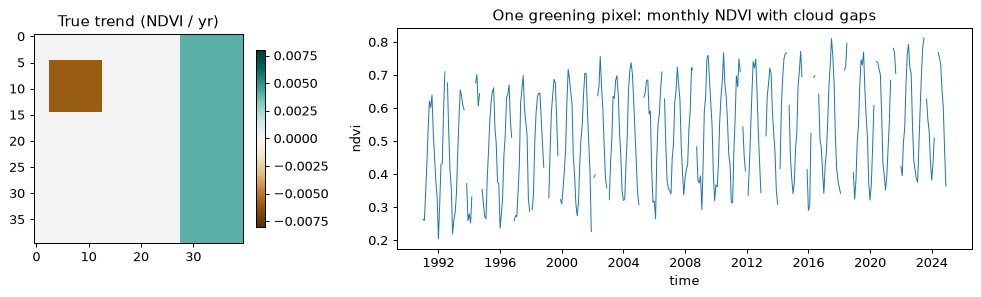

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 2.2]})
im = ax[0].imshow(true_trend, cmap="BrBG", vmin=-0.008, vmax=0.008)
ax[0].set_title("True trend (NDVI / yr)")
fig.colorbar(im, ax=ax[0], shrink=0.8)
ndvi.isel(y=2, x=30).plot(ax=ax[1], lw=0.8)
ax[1].set_title("One greening pixel: monthly NDVI with cloud gaps")
plt.tight_layout()

## 2. Growing-season composites and per-pixel trends

`annual_composite` averages April–October observations per year. It needs at least 3 clear observations, otherwise the year is NaN.
The result has a new `year` dimension, and the grid coordinates are kept.

In [4]:
annual = exr.annual_composite(ndvi, months=(4, 10), min_obs=3)
sen = exr.theil_sen(annual, min_n=10)            # robust slope (Sen 1968)
mk = exr.mann_kendall(annual, min_n=10)          # z and two-sided p (Mann 1945; Kendall 1975)
print(annual.dims, "| slope unit:", sen.attrs["slope_unit"])

('year', 'y', 'x') | slope unit: per year


## 3. Significance: raw p-values vs false-discovery-rate control

Testing 1,600 pixels at p < 0.05 flags about 5 % of the pixels where nothing changes.
On a map where most pixels do not change, those false alarms become a large share of everything that is "significant".
Benjamini–Hochberg controls that share, the false discovery rate, instead (Wilks 2016 makes this point for maps).

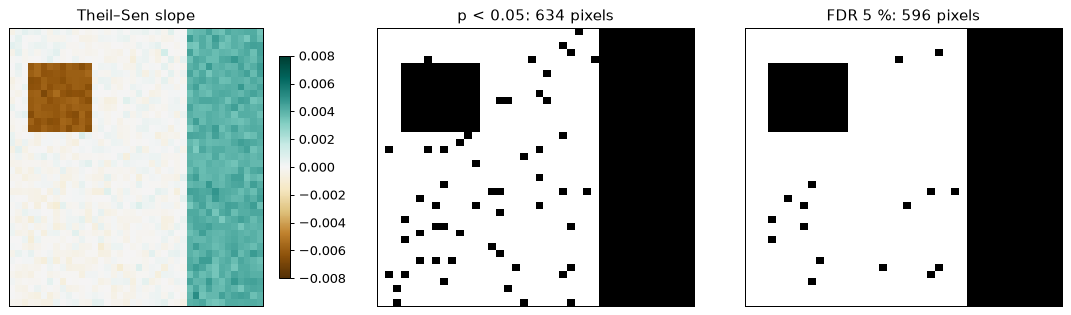

In [5]:
raw = mk["p"] < 0.05
fdr = exr.benjamini_hochberg(mk["p"], alpha=0.05)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
im = sen["slope"].plot.imshow(ax=ax[0], cmap="BrBG", vmin=-0.008, vmax=0.008, add_colorbar=False)
fig.colorbar(im, ax=ax[0], shrink=0.8)
ax[0].set_title("Theil–Sen slope")
raw.plot.imshow(ax=ax[1], cmap="Greys", add_colorbar=False)
ax[1].set_title(f"p < 0.05: {int(raw.sum())} pixels")
fdr.plot.imshow(ax=ax[2], cmap="Greys", add_colorbar=False)
ax[2].set_title(f"FDR 5 %: {int(fdr.sum())} pixels")
for a in ax:
    a.set_xlabel("")
    a.set_ylabel("")
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()

In [6]:
table = pd.DataFrame({
    "zone": zone.ravel(),
    "true_slope": true_trend.ravel(),
    "theil_sen": sen["slope"].values.ravel(),
    "raw_p<0.05": raw.values.ravel(),
    "fdr": fdr.values.ravel(),
})
summary = table.groupby("zone").agg(
    pixels=("true_slope", "size"),
    true_slope=("true_slope", "first"),
    mean_estimate=("theil_sen", "mean"),
    detected_raw_pct=("raw_p<0.05", lambda s: 100 * s.mean()),
    detected_fdr_pct=("fdr", lambda s: 100 * s.mean()),
)
display(summary.round(4))

truth = table["true_slope"] != 0
for name, col in [("raw p < 0.05", "raw_p<0.05"), ("Benjamini–Hochberg 5 %", "fdr")]:
    hits = table[col]
    print(f"{name:24s}: {int(hits.sum()):4d} detections, of which false: {int((hits & ~truth).sum()):3d} "
          f"({100 * (hits & ~truth).sum() / hits.sum():.1f} %)")

,pixels,true_slope,mean_estimate,detected_raw_pct,detected_fdr_pct
zone,,,,,
browning,100,-0.006,-0.0061,100.0000,100.0000
greening,480,0.004,0.0040,100.0000,100.0000
no trend,1020,0.000,-0.0001,5.2941,1.5686


raw p < 0.05            :  634 detections, of which false:  54 (8.5 %)
Benjamini–Hochberg 5 %  :  596 detections, of which false:  16 (2.7 %)


**Reading the table**

- **Slopes are recovered.** The Theil–Sen estimates match the true slopes in both trend zones.
- **Raw p-values over-detect.** In the no-trend zone, p < 0.05 flags about 5 % of the pixels, as expected by chance. Those false alarms make up a sizeable share of all detections.
- **FDR control keeps that share below 5 %** and still detects the real trends in close to 100 % of their pixels. It does not remove every false alarm: it bounds their proportion among the detections.

## 4. Climatology and standardized anomalies

The baseline is 1991–2020, the 30-year normal recommended by WMO (2017); a shorter baseline triggers a warning.
Each month is compared with the same calendar month of the baseline.

In [7]:
clim = exr.climatology(ndvi, baseline=(1991, 2020), by="month")
z = exr.standardized_anomalies(ndvi, clim, min_n=20)
print(clim)

<xarray.Dataset> Size: 461kB
Dimensions:  (y: 40, x: 40, month: 12)
Coordinates:
  * y        (y) float64 320B 4.5e+06 4.5e+06 4.5e+06 ... 4.496e+06 4.496e+06
  * x        (x) float64 320B 5.2e+06 5.2e+06 5.2e+06 ... 5.204e+06 5.204e+06
  * month    (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
Data variables:
    mean     (month, y, x) float64 154kB 0.2549 0.2522 0.2428 ... 0.3374 0.3373
    std      (month, y, x) float64 154kB 0.03352 0.03236 ... 0.04236 0.04504
    n        (month, y, x) int64 154kB 26 29 27 29 28 30 ... 28 27 27 25 25 28
Attributes:
    baseline_first:  1991
    baseline_last:   2020


,pixels,median z,share z < -1.5
drought,400.0,-3.97,0.88
"greening, no drought",480.0,1.43,0.00
"no trend, no drought",620.0,-0.04,0.08


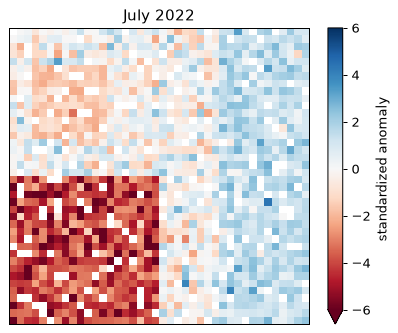

In [8]:
july22 = z.sel(time="2022-07-01")
fig, ax = plt.subplots(figsize=(4.6, 3.8))
july22.plot.imshow(ax=ax, cmap="RdBu", vmin=-6, vmax=6, cbar_kwargs={"label": "standardized anomaly"})
ax.set_title("July 2022")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()

areas = {"drought": drought_area & (zone == "no trend"),
         "greening, no drought": (zone == "greening") & ~drought_area,
         "no trend, no drought": (zone == "no trend") & ~drought_area}
pd.DataFrame({k: {"pixels": int(m.sum()), "median z": float(np.nanmedian(july22.values[m])),
                  "share z < -1.5": float(np.nanmean(july22.values[m] < -1.5))}
              for k, m in areas.items()}).T.round(2)

The drought stands out with strongly negative anomalies.

Unchanged pixels stay near zero. Note what happens in the greening strip: against a fixed 1991–2020 baseline it shows **positive** anomalies in 2022.
That is the trend, not a wet summer. A fixed baseline does not remove long-term change, so read anomaly maps alongside the trend map.

## 5. The same analysis, lazily, on chunked data

Real image stacks rarely fit in memory. With dask-backed input, nothing is computed until the values are needed.
Space is processed chunk by chunk, and time is kept whole for each pixel. The answers are identical.

In [9]:
lazy = ndvi.chunk({"time": 120, "y": 20, "x": 20})
mk_lazy = exr.mann_kendall(exr.annual_composite(lazy, months=(4, 10), min_obs=3), min_n=10)
print("still lazy:", mk_lazy["z"].chunks is not None)
print("identical to the in-memory result:", np.array_equal(mk_lazy["z"].values, mk["z"].values, equal_nan=True))

still lazy: True


identical to the in-memory result: True


## With real data

Only the data source changes. For example, Landsat Collection 2 from Microsoft Planetary Computer (needs network and `pip install eolandscape[stac]`):

```python
from eolandscape.loaders import stac

items = stac.search("landsat-c2-l2", bbox, "1991-01-01", "2024-12-31", query={"eo:cloud_cover": {"lt": 70}})
ds = stac.load(items, ["red", "nir08", "qa_pixel"], crs="EPSG:3035", resolution=30, bbox=bbox,
               chunks={"x": 1024, "y": 1024})
red, nir = exr.landsat_c2_reflectance(ds["red"]), exr.landsat_c2_reflectance(ds["nir08"])
ndvi = exr.ndvi(nir, red).where(exr.landsat_qa_clear(ds["qa_pixel"]))
# ... then steps 2-4 exactly as above
```

**References:** Mann (1945); Kendall (1975); Sen (1968); Benjamini & Hochberg (1995); Wilks (2016); WMO (2017).
The full list with DOIs is in the [README](../README.md#references).